# Chapter 7 : Combining Different Models for Ensemble Learning

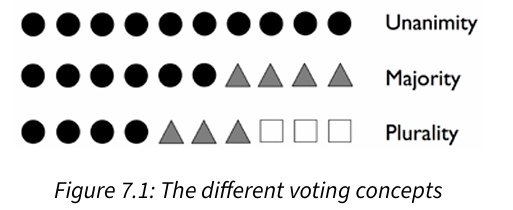

- Majority Voting: In this case we are looking for the class with the highest vote.

- Different Algorithms 

- Same Algorithm different subsets of the dataset 

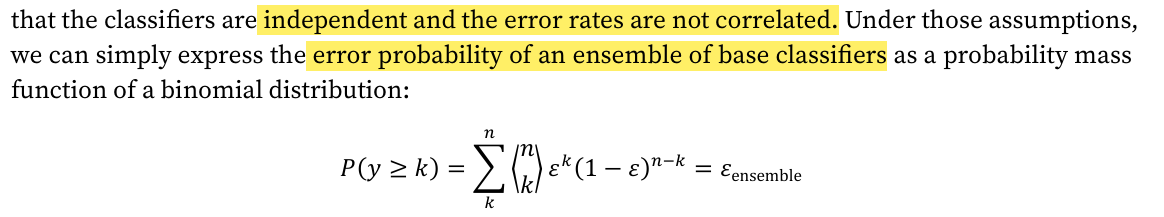

In [1]:
from scipy.special import comb 
import math 

def ensamble_error(n_classifier , error): 
    k_start = int(math.ceil(n_classifier/2.))
    probs = [comb(n_classifier,k)*error**k * (1-error)**(n_classifier - k)
    for k in range(k_start,n_classifier+1)]
    return sum(probs)

ensamble_error(n_classifier=11, error=0.25)

0.03432750701904297

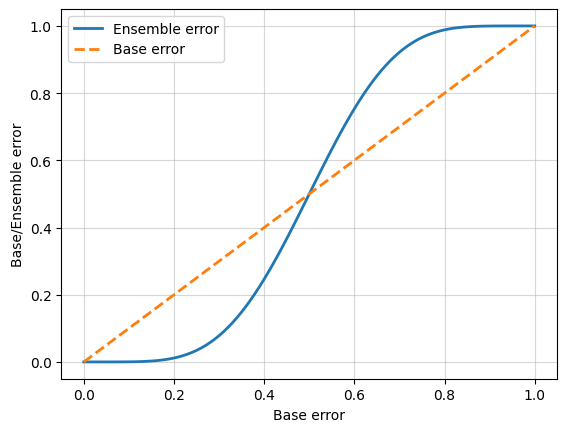

In [3]:
import numpy as np
import matplotlib.pyplot as plt
error_range = np.arange(0.0, 1.01, 0.01)
ens_errors = [ensamble_error(n_classifier=11, error=error)
                for error in error_range]
plt.plot(error_range, ens_errors,
           label='Ensemble error',
          linewidth=2)
plt.plot(error_range, error_range,
          linestyle='--', label='Base error',
           linewidth=2)
plt.xlabel('Base error')
plt.ylabel('Base/Ensemble error')
plt.legend(loc='upper left')
plt.grid(alpha=0.5)
plt.show()

###  Implementing a simple majority vote classifier

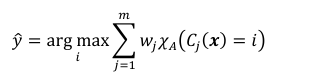

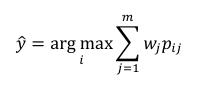

- this is Equivalent to the mode of of the predictions of each classifier. 

- Models like Logistic regression gives us the probabilities of a certain class. 

In [4]:
np.argmax(np.bincount([0,0,1], 
                      weights = [0.2 , 0.2 , 0.6]))

1

In [6]:
ex  = np.array([[0.9, 0.1] , [0.8 , 0.2] , [0.4 , 0.6]])

p = np.average(ex , axis = 0 , weights=[0.2,0.2,0.2]
               )

print(p)

np.argmax(p)

[0.7 0.3]


0

In [23]:
from sklearn.base import BaseEstimator
from sklearn.base import ClassifierMixin
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone
from sklearn.pipeline import _name_estimators
import numpy as np
import operator

class MajorityVoteClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, classifiers, vote='classlabel', weights=None):
        self.classifiers = classifiers
        self.named_classifiers = {
            key: value for key,
            value in _name_estimators(classifiers)
        }
        self.vote = vote
        self.weights = weights

    def fit(self, X, y):
        if self.vote not in ('probability', 'classlabel'):
            raise ValueError(f"vote must be 'probability' "
            f"or 'classlabel'"
            f"; got (vote={self.vote})")
        
        if self.weights and len(self.weights) != len(self.classifiers):
            raise ValueError(f'Number of classifiers and'
            f' weights must be equal'
            f'; got {len(self.weights)} weights,'
            f' {len(self.classifiers)} classifiers')
        
        # Use LabelEncoder to ensure class labels start
        # with 0, which is important for np.argmax
        # call in self.predict
        self.lablenc_ = LabelEncoder()
        self.lablenc_.fit(y)
        self.classes_ = self.lablenc_.classes_
        self.classifiers_ = []
        for clf in self.classifiers:
            fitted_clf = clone(clf).fit(X,
                                    self.lablenc_.transform(y))
            self.classifiers_.append(fitted_clf)
        return self

    def predict(self, X):
        if self.vote == 'probability':
            maj_vote = np.argmax(self.predict_proba(X), axis=1)
        else: # 'classlabel' vote
            predictions = np.asarray([
                clf.predict(X) for clf in self.classifiers_
            ]).T
            maj_vote = np.apply_along_axis(
                lambda x: np.argmax(
                    np.bincount(x, weights=self.weights)
                ),
                axis=1, arr=predictions
            )
        maj_vote = self.lablenc_.inverse_transform(maj_vote)
        return maj_vote

    def predict_proba(self, X):
        probas = np.asarray([clf.predict_proba(X)
            for clf in self.classifiers_])
        avg_proba = np.average(probas, axis=0,
                            weights=self.weights)
        return avg_proba

    def get_params(self, deep=True):
        if not deep:
            return super().get_params(deep=False)
        else:
            out = self.named_classifiers.copy()
            for name, step in self.named_classifiers.items():
                for key, value in step.get_params(
                                deep=True).items():
                    out[f'{name}__{key}'] = value
            return out

In [24]:
from sklearn import datasets 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
iris = datasets.load_iris()
X,y = iris.data[50:,[1,2]],iris.target[50:]
le = LabelEncoder()
y = le.fit_transform(y)

In [27]:
X_train, X_test, y_train, y_test =\
   train_test_split(X, y,
                      test_size=0.5,
                      random_state=1)

In [34]:
!pip install xgboost

   ---------------------------------------- 0.0/56.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/56.8 MB ? eta -:--:--
   ---- ----------------------------------- 5.8/56.8 MB 22.0 MB/s eta 0:00:03
   ---- ----------------------------------- 7.1/56.8 MB 15.6 MB/s eta 0:00:04
   ----------- ---------------------------- 15.7/56.8 MB 23.6 MB/s eta 0:00:02
   ---------------- ----------------------- 23.9/56.8 MB 27.0 MB/s eta 0:00:02
   ---------------------- ----------------- 31.7/56.8 MB 28.8 MB/s eta 0:00:01
   ---------------------------- ----------- 40.1/56.8 MB 30.7 MB/s eta 0:00:01
   --------------------------------- ------ 47.4/56.8 MB 31.5 MB/s eta 0:00:01
   -------------------------------------- - 55.3/56.8 MB 32.0 MB/s eta 0:00:01
   ---------------------------------------- 56.8/56.8 MB 30.7 MB/s eta 0:00:00


###  Bagging – building an ensemble of classifiers from bootstrap samples

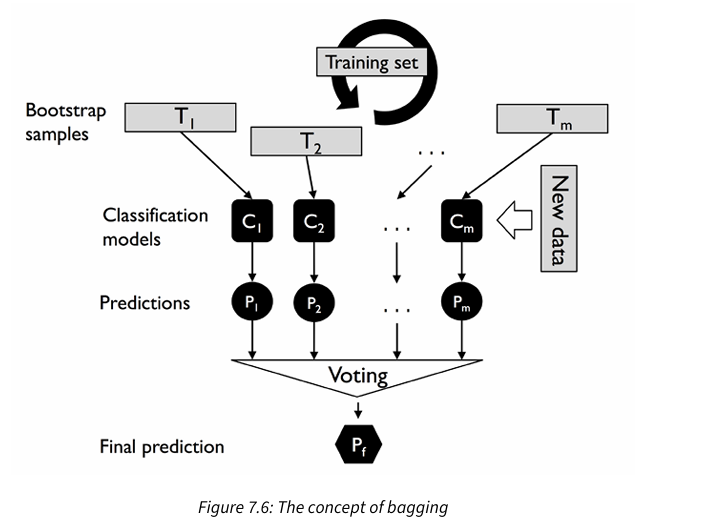

- In this meta-classifier we are selecing subsets of the data with replaciment and  using that to train our models.


- bagging is ineffective in reducing model bias, that is, models that are too simple to capture the trends 
    in the data well. This is why we want to perform bagging on an ensemble of classifiers with low bias, 
    for example, unpruned decision trees.

In [45]:
import pandas as pd
df_wine = pd.read_csv('https://archive.ics.uci.edu/ml/'
                        'machine-learning-databases/'
                        'wine/wine.data',
                        header=None)
df_wine.columns = ['Class label', 'Alcohol',
                    'Malic acid', 'Ash',
                     'Alcalinity of ash',
                     'Magnesium', 'Total phenols',
                     'Flavanoids', 'Nonflavanoid phenols',
                     'Proanthocyanins',
                     'Color intensity', 'Hue',
                     'OD280/OD315 of diluted wines',
                     'Proline']
 # drop 1 class
df_wine = df_wine[df_wine['Class label'] != 1]
y = df_wine['Class label'].values
X = df_wine[['Alcohol',
               'OD280/OD315 of diluted wines']].values

In [46]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split 

le = LabelEncoder()

y = le.fit_transform(y)

X_train , X_test , y_train , y_test = train_test_split(X,y , test_size=0.2 , random_state=1 , stratify=y)

In [47]:
from sklearn.ensemble import BaggingClassifier 
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

tree = DecisionTreeClassifier(criterion="entropy" , random_state=1 , max_depth=None)

bag = BaggingClassifier(estimator=tree , 
                        n_estimators=500 , 
                        max_samples=1.0,
                        max_features=1.0,
                        bootstrap=True, 
                        bootstrap_features=False, 
                        n_jobs=1,
                        random_state= 1)





tree = tree.fit(X_train, y_train)
y_train_pred = tree.predict(X_train)
y_test_pred = tree.predict(X_test)
tree_train = accuracy_score(y_train, y_train_pred)
tree_test = accuracy_score(y_test, y_test_pred)
print(f'Decision tree train/test accuracies '
        f'{tree_train:.3f}/{tree_test:.3f}')

bag = bag.fit(X_train, y_train)
y_train_pred = bag.predict(X_train)
y_test_pred = bag.predict(X_test)
bag_train = accuracy_score(y_train, y_train_pred)
bag_test = accuracy_score(y_test, y_test_pred)
print(f'Bagging train/test accuracies '
       f'{bag_train:.3f}/{bag_test:.3f}')

Decision tree train/test accuracies 1.000/0.833
Bagging train/test accuracies 1.000/0.917


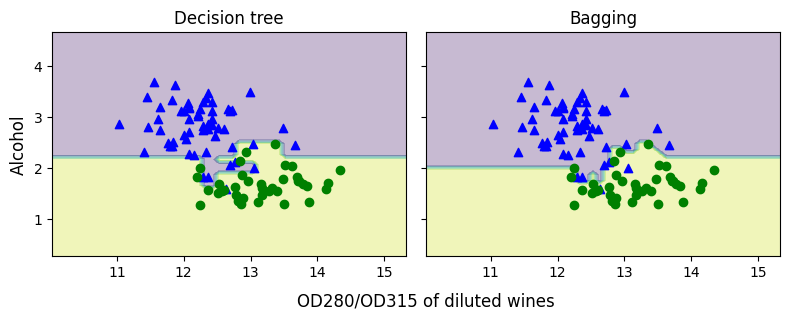

In [49]:
x_min = X_train[:, 0].min() - 1
x_max = X_train[:, 0].max() + 1
y_min = X_train[:, 1].min() - 1
y_max = X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                      np.arange(y_min, y_max, 0.1))
f, axarr = plt.subplots(nrows=1, ncols=2,
                          sharex='col',
                          sharey='row',
                          figsize=(8, 3))
for idx, clf, tt in zip([0, 1],
                          [tree, bag],
                          ['Decision tree', 'Bagging']):
      clf.fit(X_train, y_train)
 
      Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
      Z = Z.reshape(xx.shape)
      axarr[idx].contourf(xx, yy, Z, alpha=0.3)
      axarr[idx].scatter(X_train[y_train==0, 0],
                         X_train[y_train==0, 1],
                         c='blue', marker='^')
      axarr[idx].scatter(X_train[y_train==1, 0],
                         X_train[y_train==1, 1],
                         c='green', marker='o')
      axarr[idx].set_title(tt)
axarr[0].set_ylabel('Alcohol', fontsize=12)
plt.tight_layout()
plt.text(0, -0.2,
           s='OD280/OD315 of diluted wines',
           ha='center',
           va='center',
           fontsize=12,
           transform=axarr[1].transAxes)
plt.show()

#### Leveraging weak learners via adaptive boosting

-  The key concept behind boosting is to focus on training examples that are hard to classify, that is, to let the weak learners subsequently learn from misclassified training examples to improve the performance of the ensemble.

- Initial Boosting Algorithm can be seen below. 


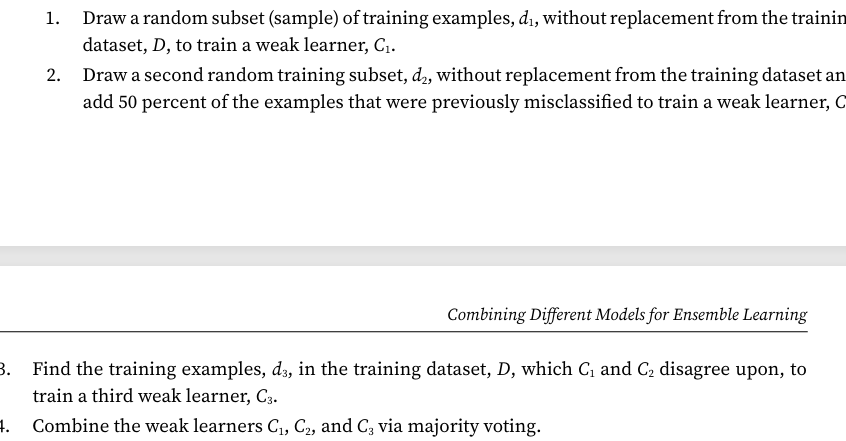

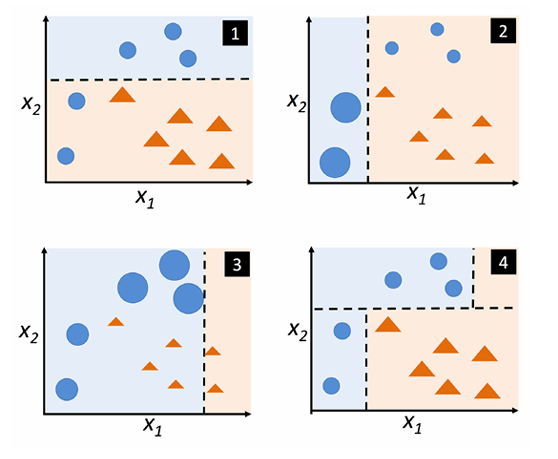

1. Start by intializing training dataset with equal weights 

2. we assign a larger weight to the two previously misclassified examples (circles). Furthermore, we lower the weight of the correctly classified examples.

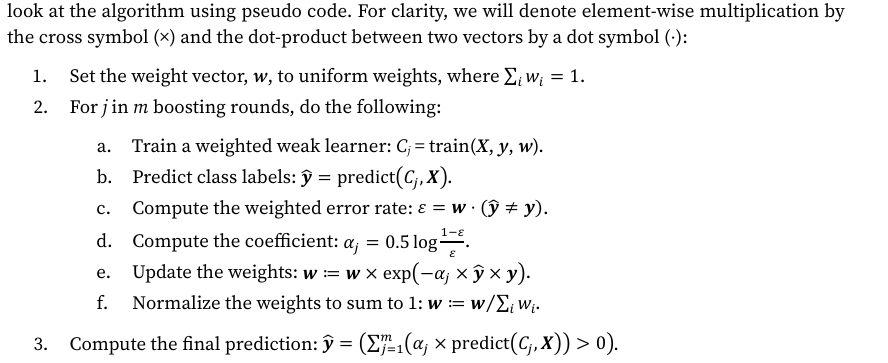

In [50]:
y = np.array([1, 1, 1, -1, -1, -1,  1,  1,  1, -1])
yhat = np.array([1, 1, 1, -1, -1, -1, -1, -1, -1, -1])
correct = (y == yhat)
weights = np.full(10, 0.1)
print(weights)
epsilon = np.mean(~correct)
print(epsilon)

[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
0.3


In [51]:
alpha_j = 0.5 * np.log((1-epsilon)/(epsilon))
print(alpha_j)

0.42364893019360184


In [52]:
update_if_correct = 0.1 * np.exp(-alpha_j * 1 * 1)
print(update_if_correct)

0.06546536707079771


In [54]:
update_if_wrong_1 = 0.1 * np.exp(-alpha_j * 1 * -1)
print(update_if_wrong_1)

0.1527525231651947


In [55]:
weights = np.where(correct == 1,
                     update_if_correct,
                    update_if_wrong_1)
print(weights)

[0.06546537 0.06546537 0.06546537 0.06546537 0.06546537 0.06546537
 0.15275252 0.15275252 0.15275252 0.06546537]


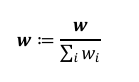

In [56]:
# After Updating we normalize values 
normalized_weights = weights / np.sum(weights)
print(normalized_weights)

[0.07142857 0.07142857 0.07142857 0.07142857 0.07142857 0.07142857
 0.16666667 0.16666667 0.16666667 0.07142857]


### Applying AdaBoost using scikit-learn

In [58]:
from sklearn.ensemble import AdaBoostClassifier
tree = DecisionTreeClassifier(criterion='entropy',
                                random_state=1,
                                max_depth=1)
ada = AdaBoostClassifier(estimator=tree,
                           n_estimators=500,
                           learning_rate=0.1,
                           random_state=1)
tree = tree.fit(X_train, y_train)
y_train_pred = tree.predict(X_train)
y_test_pred = tree.predict(X_test) 
tree_train = accuracy_score(y_train, y_train_pred)
tree_test = accuracy_score(y_test, y_test_pred)
print(f'Decision tree train/test accuracies '
        f'{tree_train:.3f}/{tree_test:.3f}')

Decision tree train/test accuracies 0.916/0.875


In [59]:
ada = ada.fit(X_train, y_train)
y_train_pred = ada.predict(X_train)
y_test_pred = ada.predict(X_test)
ada_train = accuracy_score(y_train, y_train_pred)
ada_test = accuracy_score(y_test, y_test_pred)
print(f'AdaBoost train/test accuracies '
       f'{ada_train:.3f}/{ada_test:.3f}')

AdaBoost train/test accuracies 0.968/0.917


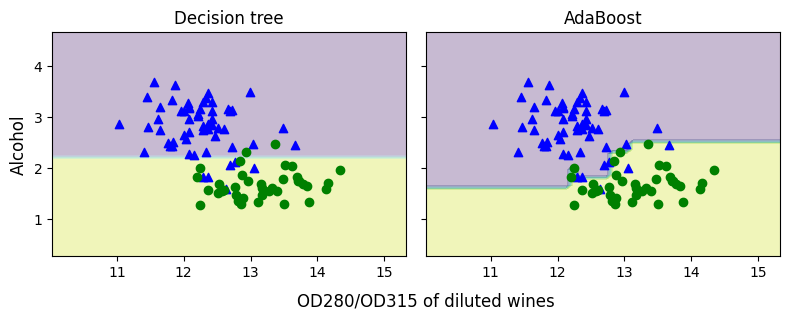

In [65]:

x_min = X_train[:, 0].min() - 1
x_max = X_train[:, 0].max() + 1
y_min = X_train[:, 1].min() - 1
y_max = X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                      np.arange(y_min, y_max, 0.1))
f, axarr = plt.subplots(1, 2,
                         sharex='col',
                         sharey='row',
                         figsize=(8,3))

for idx, clf, tt in zip([0, 1],
                         [tree, ada],
                         ['Decision tree', 'AdaBoost']):
     clf.fit(X_train, y_train)
     Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
     Z = Z.reshape(xx.shape)
     axarr[idx].contourf(xx, yy, Z, alpha=0.3)
     axarr[idx].scatter(X_train[y_train==0, 0],
                        X_train[y_train==0, 1],
                        c='blue',
                        marker='^')
     axarr[idx].scatter(X_train[y_train==1, 0],
                        X_train[y_train==1, 1],
                        c='green',
                        marker='o')
     axarr[idx].set_title(tt)
     axarr[0].set_ylabel('Alcohol', fontsize=12)

plt.tight_layout()
plt.text(0, -0.2,
 
          s='OD280/OD315 of diluted wines',
          ha='center',
          va='center',
          fontsize=12,
          transform=axarr[1].transAxes)
plt.show()

### Gradient boosting – training an ensemble based on loss gradients

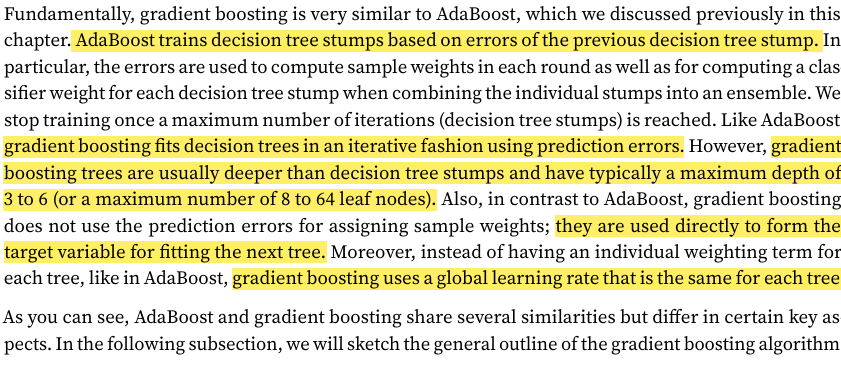

-  AdaBoost trains decision tree stumps based on errors of the previous decision tree stump.  

- gradient boosting fits decision trees in an iterative fashion using prediction errors

-  gradient boosting trees are usually deeper than decision tree stumps and have typically a maximum depth of 
  3 to 6 (or a maximum number of 8 to 64 leaf nodes).

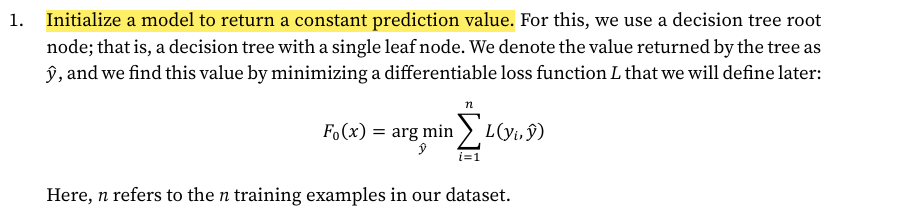

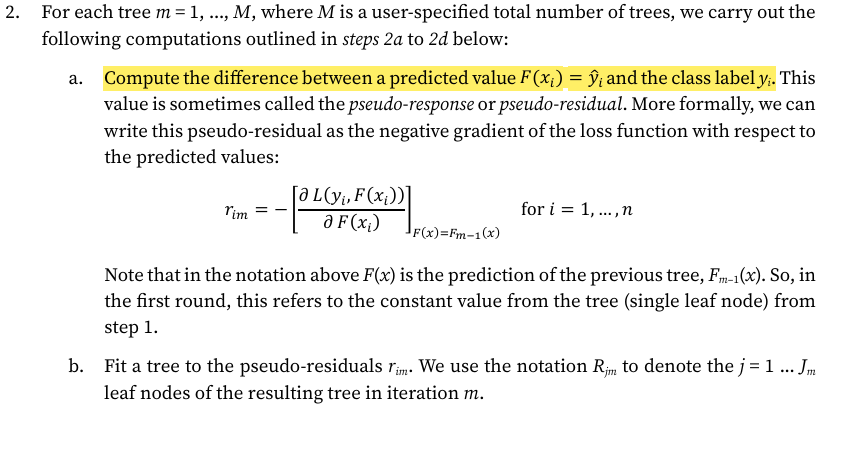

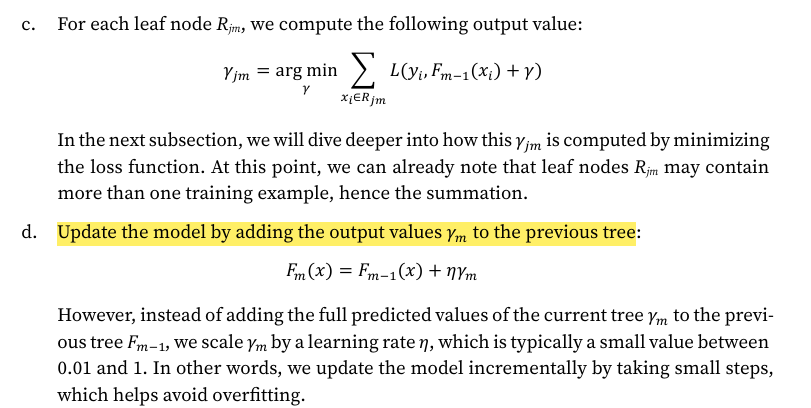

#### Using XGBoost

In [66]:
! pip install XGBoost==1.5.0

   ---------------------------------------- 0.0/106.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/106.6 MB ? eta -:--:--
   - -------------------------------------- 3.1/106.6 MB 12.3 MB/s eta 0:00:09
   - -------------------------------------- 4.2/106.6 MB 10.1 MB/s eta 0:00:11
   - -------------------------------------- 5.0/106.6 MB 7.0 MB/s eta 0:00:15
   -- ------------------------------------- 6.8/106.6 MB 7.5 MB/s eta 0:00:14
   --- ------------------------------------ 8.7/106.6 MB 7.7 MB/s eta 0:00:13
   ---- ----------------------------------- 10.7/106.6 MB 8.1 MB/s eta 0:00:12
   ---- ----------------------------------- 12.6/106.6 MB 8.3 MB/s eta 0:00:12
   ----- ---------------------------------- 14.4/106.6 MB 8.2 MB/s eta 0:00:12
   ------ --------------------------------- 16.5/106.6 MB 8.3 MB/s eta 0:00:11
   ------ --------------------------------- 18.6/106.6 MB 8.4 MB/s eta 0:00:11
   ------- -------------------------------- 19.9/106.6 MB 8.6 MB/s eta 

  You can safely remove it manually.


In [72]:
import xgboost as xgb 

model = xgb.XGBClassifier(n_estimators = 1000 , learning_rate = 0.01 , 
                         max_depth=4 , random_state=1 , use_label_encoder=False)

gbm = model.fit(X_train , y_train)

y_train_pred = gbm.predict(X_train)
y_test_pred = gbm.predict(X_test)

gbm_train = accuracy_score(y_train , y_train_pred)
gbm_test = accuracy_score(y_test , y_test_pred)

print(f"XGBOOST train/test accuracies " f"{gbm_train:.3f}/{gbm_test:.3f}")

c:\Users\muham\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [12:05:35] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  


XGBOOST train/test accuracies 0.968/0.917
